# Phase 10 — Official Evaluation & Fairness Audit

**Goal:** Run the **unmodified** `tools/evaluate.py` (the same scorer the organisers use) on the
Phase 9 predictions for the May–June validation window.  Report every component of the official score,
the per-group fairness audit, the confusion matrix, calibration metrics, and a multi-phase comparison.

**Inputs:** `reports/phase9_validation_predictions.csv` (return_id, decision, confidence, justification)
produced by Phase 9.

**No hidden Jul–Sep labels are used at any point.**

## 1 · Imports & paths

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from r2sorter.config import load_config
from r2sorter.data import load_all
from r2sorter.scoring import official_score
from r2sorter.protocol import build_protocol

CFG  = load_config(ROOT / "config.yaml")
DATA = load_all(CFG)

PRED_PATH  = ROOT / "reports" / "phase9_validation_predictions.csv"
FIG_DIR    = ROOT / "reports" / "figures"
REP_DIR    = ROOT / "reports"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# truth for the test (May–Jun) window — label column already in protocol.parts["test"]
protocol = build_protocol(CFG, DATA, seed=0)
truth_df = protocol.parts["test"].copy()

print(f"Truth rows: {len(truth_df):,}")
print("Label distribution:")
print(truth_df["label"].value_counts().to_string())

Truth rows: 8,497
Label distribution:
label
genuine_fit_issue        4193
genuine_quality_issue    2453
genuine_wrong_item       1152
abusive                   699


## 2 · Run official scorer (tools/evaluate.py, unmodified)

In [2]:
preds = pd.read_csv(PRED_PATH)
print(f"Predictions loaded: {len(preds):,} rows")
print(f"Decision distribution:\n{preds['decision'].value_counts().to_string()}")
print()

# run through the official scoring wrapper
result = official_score(preds, truth_df)

# print the full official report
print("=" * 72)
print("OFFICIAL SCORE REPORT")
print("=" * 72)
c = result["components"]
print(f"\nPRIMARY SCORE = {result['primary_score']:.6f}")
print(f"  savings            = {c['savings']:.6f}")
print(f"  fairness_score     = {c['fairness_score']:.6f}")
print(f"  fairness_credit    = {c['fairness_credit']:.6f}  (= min(1, max(0, savings) / 0.20))")
print(f"  fairness_effective = {c['fairness_effective']:.6f}  (= fairness_score × credit)")
print(f"  size_chart_score   = {c['size_chart_score']:.6f}  (scored by organisers on hidden truth)")
print()
print(f"  Formula: 0.7 × {c['savings']:.4f} + 0.2 × {c['fairness_effective']:.4f} + 0.1 × {c['size_chart_score']:.4f}")
print(f"         = {result['primary_score']:.6f}")
print()
cr = result["cost"]
print(f"Cost breakdown:")
print(f"  all-auto_approve baseline: {cr['all_auto_approve_total']:.1f}")
print(f"  oracle (best possible):    {cr['oracle_total']:.1f}")
print(f"  team total:                {cr['team_total']:.1f}")
print(f"  mean per request:          {cr['team_mean_per_request']:.6f}")

Predictions loaded: 8,497 rows
Decision distribution:
decision
auto_approve    8056
inspect          386
escalate          55

OFFICIAL SCORE REPORT

PRIMARY SCORE = 0.349273
  savings            = 0.277539
  fairness_score     = 0.774977
  fairness_credit    = 1.000000  (= min(1, max(0, savings) / 0.20))
  fairness_effective = 0.774977  (= fairness_score × credit)
  size_chart_score   = 0.000000  (scored by organisers on hidden truth)

  Formula: 0.7 × 0.2775 + 0.2 × 0.7750 + 0.1 × 0.0000
         = 0.349273

Cost breakdown:
  all-auto_approve baseline: 699.0
  oracle (best possible):    0.0
  team total:                505.0
  mean per request:          0.059433


## 3 · Fairness audit — per-group breakdown

In [3]:
print("Fairness audit (genuine customers only):")
print("-" * 72)
fairness_rows = []
for pair_name, v in result["fairness"].items():
    print(f"\n{pair_name}")
    print(f"  {v['group_a']:25s}: {v['flagged_a']:4d}/{v['n_genuine_a']:5d} flagged "
          f"({v['flag_rate_a']:.2%} raw; {v['smoothed_rate_a']:.2%} smoothed)")
    print(f"  {v['group_b']:25s}: {v['flagged_b']:4d}/{v['n_genuine_b']:5d} flagged "
          f"({v['flag_rate_b']:.2%} raw; {v['smoothed_rate_b']:.2%} smoothed)")
    print(f"  Disparity ratio: {v['disparity_ratio']:.4f}x  "
          f"(95% CI {v['ratio_95ci_bootstrap'][0]:.3f}–{v['ratio_95ci_bootstrap'][1]:.3f})")
    print(f"  Pair score: {v['score']:.4f}  (1.0 = perfectly equal)")
    fairness_rows.append({
        "group_pair": pair_name,
        "flag_rate_a": v["flag_rate_a"],
        "flag_rate_b": v["flag_rate_b"],
        "disparity_ratio": v["disparity_ratio"],
        "ci_lo": v["ratio_95ci_bootstrap"][0],
        "ci_hi": v["ratio_95ci_bootstrap"][1],
        "pair_score": v["score"],
        "group_a": v["group_a"],
        "group_b": v["group_b"],
    })

fairness_df = pd.DataFrame(fairness_rows)
fairness_df.to_csv(REP_DIR / "phase10_fairness_audit.csv", index=False)
print(f"\nSaved reports/phase10_fairness_audit.csv")

Fairness audit (genuine customers only):
------------------------------------------------------------------------

new_vs_established_customer
  new (<90 days)           :    7/ 1021 flagged (0.69% raw; 1.69% smoothed)
  established              :   86/ 6777 flagged (1.27% raw; 2.27% smoothed)
  Disparity ratio: 1.3461x  (95% CI 1.034–1.868)
  Pair score: 0.6539  (1.0 = perfectly equal)

low_value_vs_other_order
  low value (<1000)        :   23/ 2288 flagged (1.00% raw; 2.00% smoothed)
  1000+                    :   70/ 5510 flagged (1.27% raw; 2.27% smoothed)
  Disparity ratio: 1.1322x  (95% CI 1.007–1.449)
  Pair score: 0.8678  (1.0 = perfectly equal)

non_english_vs_english_text
  non-English              :   37/ 3741 flagged (0.99% raw; 1.99% smoothed)
  English                  :   56/ 4057 flagged (1.38% raw; 2.38% smoothed)
  Disparity ratio: 1.1967x  (95% CI 1.012–1.509)
  Pair score: 0.8033  (1.0 = perfectly equal)

Saved reports/phase10_fairness_audit.csv


## 4 · Fairness chart

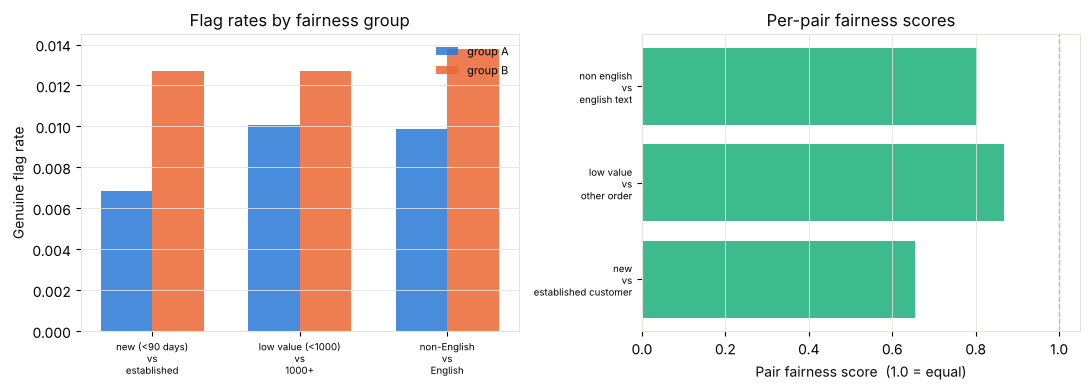

Saved phase10_fairness_audit.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# left: flag rates per group pair
ax = axes[0]
x = np.arange(len(fairness_df))
w = 0.35
labels_a = fairness_df["group_a"].str[:20]
labels_b = fairness_df["group_b"].str[:20]
ax.bar(x - w/2, fairness_df["flag_rate_a"], width=w, color="#2a78d6", label="group A", alpha=0.85)
ax.bar(x + w/2, fairness_df["flag_rate_b"], width=w, color="#eb6834", label="group B", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([f"{a}\nvs\n{b}" for a, b in zip(labels_a, labels_b)], fontsize=7)
ax.set_ylabel("Genuine flag rate", color="#0b0b0b")
ax.set_title("Flag rates by fairness group", color="#0b0b0b")
ax.legend(frameon=False, fontsize=8)
ax.set_facecolor("white"); ax.grid(axis="y", color="#e4e3df", lw=0.6)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")

# right: pair scores with disparity ratio CI
ax = axes[1]
pair_labels = [p.replace("_vs_", "\nvs\n").replace("_", " ") for p in fairness_df["group_pair"]]
bars = ax.barh(x, fairness_df["pair_score"], color="#1baf7a", alpha=0.85)
xerr_lo = fairness_df["pair_score"] - np.clip(1 - (fairness_df["ci_hi"] - 1), 0, 1)
xerr_hi = np.clip(1 - (fairness_df["ci_lo"] - 1), 0, 1) - fairness_df["pair_score"]
ax.set_yticks(x); ax.set_yticklabels(pair_labels, fontsize=7)
ax.axvline(1.0, color="#b9b8b2", lw=1, ls="--")
ax.set_xlim(0, 1.05)
ax.set_xlabel("Pair fairness score  (1.0 = equal)", color="#0b0b0b")
ax.set_title("Per-pair fairness scores", color="#0b0b0b")
ax.set_facecolor("white"); ax.grid(axis="x", color="#e4e3df", lw=0.6)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")

fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase10_fairness_audit.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase10_fairness_audit.png")

## 5 · Confusion matrix (truth label × decision)

Confusion matrix (rows = truth label, columns = decision):
                       auto_approve  inspect  escalate
abusive                         351      295        53
genuine_quality_issue          2401       51         1
genuine_fit_issue              4157       35         1
genuine_wrong_item             1147        5         0

Row-normalised (what % of each true label gets each decision):
                       auto_approve  inspect  escalate
abusive                       0.502    0.422     0.076
genuine_quality_issue         0.979    0.021     0.000
genuine_fit_issue             0.991    0.008     0.000
genuine_wrong_item            0.996    0.004     0.000

Saved reports/phase10_confusion_matrix.csv


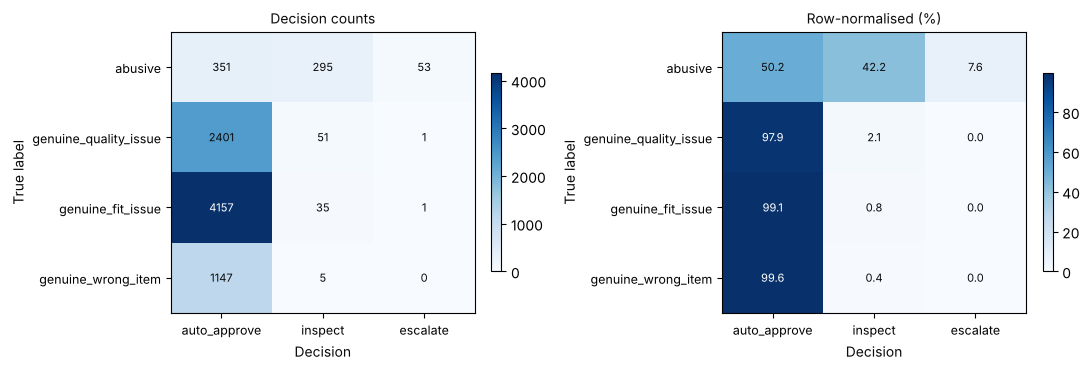

Saved phase10_confusion_matrix.png


In [5]:
from r2sorter.router import DECISIONS
LABELS = ["abusive", "genuine_quality_issue", "genuine_fit_issue", "genuine_wrong_item"]

conf = result["confusion_truth_by_decision"]
conf_df = pd.DataFrame(
    {d: [conf[lab][d] for lab in LABELS] for d in DECISIONS},
    index=LABELS,
)
print("Confusion matrix (rows = truth label, columns = decision):")
print(conf_df.to_string())
print()

# as percentages (row-normalised)
conf_pct = conf_df.div(conf_df.sum(axis=1), axis=0).round(3)
print("Row-normalised (what % of each true label gets each decision):")
print(conf_pct.to_string())

# save
conf_df.to_csv(REP_DIR / "phase10_confusion_matrix.csv")
print("\nSaved reports/phase10_confusion_matrix.csv")

# heatmap
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, data, title, fmt in zip(
    axes,
    [conf_df, conf_pct * 100],
    ["Decision counts", "Row-normalised (%)"],
    [".0f", ".1f"],
):
    im = ax.imshow(data.values, aspect="auto", cmap="Blues")
    ax.set_xticks(range(len(DECISIONS))); ax.set_xticklabels(DECISIONS, fontsize=9)
    ax.set_yticks(range(len(LABELS)));   ax.set_yticklabels(LABELS, fontsize=9)
    ax.set_title(title, color="#0b0b0b", fontsize=10)
    for i in range(len(LABELS)):
        for j in range(len(DECISIONS)):
            val = data.values[i, j]
            ax.text(j, i, format(val, fmt), ha="center", va="center", fontsize=8,
                    color="white" if val > data.values.max() * 0.6 else "#0b0b0b")
    plt.colorbar(im, ax=ax, fraction=0.03)
    ax.set_xlabel("Decision", color="#0b0b0b")
    ax.set_ylabel("True label", color="#0b0b0b")
fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase10_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase10_confusion_matrix.png")

## 6 · Abuse detection & confidence calibration

Abuse detection:
  Total abusive:       699
  Total genuine:       7798
  Flag precision:      0.7891  (of all flagged, how many are truly abusive)
  Flag recall:         0.4979  (of all abusive, how many are flagged)
  Genuine flag rate:   0.01193  (fraction of genuine wrongly flagged)
  Genuine escalated:   2  (genuine returns wrongly escalated — cost 10 each)
  Flags conf < 0.2:    0  (low-confidence flags worth reviewing)

Confidence as P(abusive):
  Brier score:         0.040726  (lower is better; 0 = perfect)
  ECE (10 bins):       0.012344  (lower is better; 0 = perfect calibration)
  Average precision:   0.709571  (area under PR-curve; higher is better)


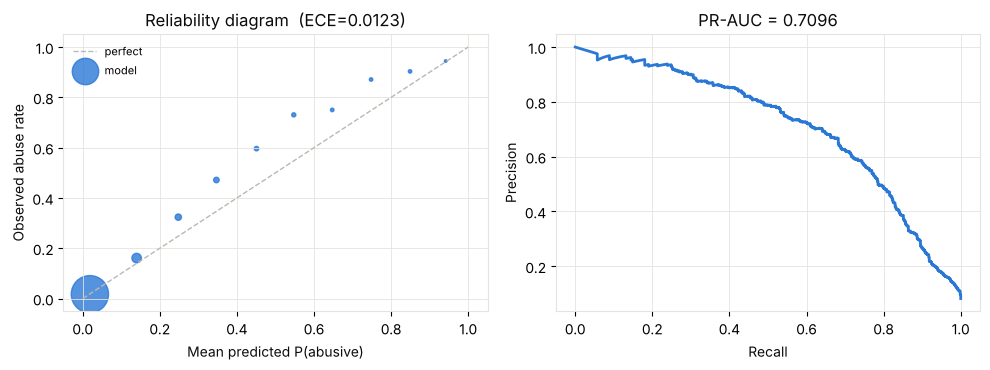

Saved phase10_calibration.png


In [6]:
ad = result["abuse_detection"]
cal = result["calibration_of_confidence_as_P_abusive"]

print("Abuse detection:")
print(f"  Total abusive:       {ad['n_abusive']}")
print(f"  Total genuine:       {ad['n_genuine']}")
print(f"  Flag precision:      {ad['flag_precision']:.4f}  (of all flagged, how many are truly abusive)")
print(f"  Flag recall:         {ad['flag_recall']:.4f}  (of all abusive, how many are flagged)")
print(f"  Genuine flag rate:   {ad['genuine_flag_rate']:.5f}  (fraction of genuine wrongly flagged)")
print(f"  Genuine escalated:   {ad['genuine_escalated']}  (genuine returns wrongly escalated — cost 10 each)")
print(f"  Flags conf < 0.2:    {ad['flags_with_confidence_below_0.2']}  (low-confidence flags worth reviewing)")
print()
print("Confidence as P(abusive):")
print(f"  Brier score:         {cal['brier']:.6f}  (lower is better; 0 = perfect)")
print(f"  ECE (10 bins):       {cal['ece_10_bins']:.6f}  (lower is better; 0 = perfect calibration)")
print(f"  Average precision:   {cal['average_precision']:.6f}  (area under PR-curve; higher is better)")

# reliability diagram  — align truth to preds order
truth_aligned = preds[["return_id"]].merge(truth_df[["return_id", "label"]], on="return_id", how="left")
p_arr = preds["confidence"].to_numpy(dtype=float)
y_arr = (truth_aligned["label"] == "abusive").to_numpy().astype(float)

bins = np.linspace(0, 1, 11)
bin_centers, mean_pred, mean_obs, counts = [], [], [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (p_arr >= lo) & (p_arr < hi)
    if mask.sum() >= 5:
        bin_centers.append((lo + hi) / 2)
        mean_pred.append(p_arr[mask].mean())
        mean_obs.append(y_arr[mask].mean())
        counts.append(mask.sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

ax = axes[0]
ax.plot([0, 1], [0, 1], color="#b9b8b2", lw=1, ls="--", label="perfect")
ax.scatter(mean_pred, mean_obs, s=[c / 10 for c in counts], color="#2a78d6", alpha=0.8, label="model")
ax.set_xlabel("Mean predicted P(abusive)", color="#0b0b0b")
ax.set_ylabel("Observed abuse rate", color="#0b0b0b")
ax.set_title(f"Reliability diagram  (ECE={cal['ece_10_bins']:.4f})", color="#0b0b0b")
ax.legend(frameon=False, fontsize=8); ax.set_facecolor("white")
ax.grid(color="#e4e3df", lw=0.6)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")

# precision-recall curve
from sklearn.metrics import precision_recall_curve, average_precision_score
prec, rec, _ = precision_recall_curve(y_arr, p_arr)
ax = axes[1]
ax.plot(rec, prec, color="#2a78d6", lw=2)
ap = average_precision_score(y_arr, p_arr)
ax.set_xlabel("Recall", color="#0b0b0b"); ax.set_ylabel("Precision", color="#0b0b0b")
ax.set_title(f"PR-AUC = {ap:.4f}", color="#0b0b0b")
ax.set_facecolor("white"); ax.grid(color="#e4e3df", lw=0.6)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")

fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase10_calibration.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase10_calibration.png")

## 7 · Multi-phase score comparison

Multi-phase comparison:
                           Official score   Savings  Fairness Baseline score Baseline fairness  Fairness effective
Phase                                                                                                             
Phase 9 (final)                  0.349300  0.277500  0.775000         0.3326            0.6577                 NaN
Phase 9 (official scorer)        0.349273  0.277539  0.774977              —                 —            0.774977

Saved reports/phase10_phase_comparison.csv


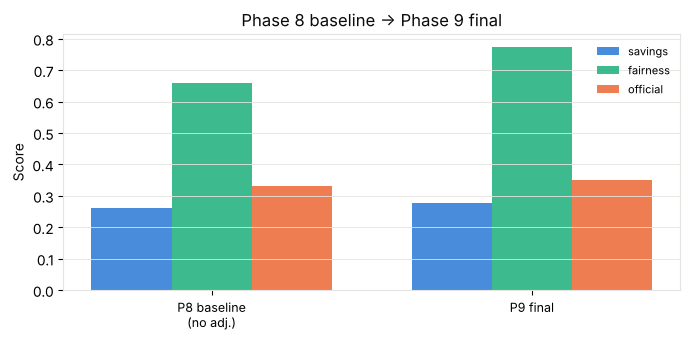

Saved phase10_phase_comparison.png


In [7]:
# load results from each phase config
phase_results = []

# Phase 5 (baselines — read from phase5 notebook outputs if available)
for phase_label, cfg_path, pred_path_key in [
    ("Phase 9 (final)", "reports/phase9_config.json", None),
]:
    with open(ROOT / cfg_path) as f:
        cfg_data = json.load(f)
    r = cfg_data.get("results", {})
    phase_results.append({
        "Phase": phase_label,
        "Official score":  r.get("final_official",    r.get("adjusted_official", "—")),
        "Savings":         r.get("final_savings",     r.get("adjusted_savings", "—")),
        "Fairness":        r.get("final_fairness",    r.get("adjusted_fairness", "—")),
        "Baseline score":  r.get("baseline_official", "—"),
        "Baseline fairness": r.get("baseline_fairness", "—"),
    })

# append the official scorer result for Phase 9
phase_results.append({
    "Phase": "Phase 9 (official scorer)",
    "Official score":     result["primary_score"],
    "Savings":            result["components"]["savings"],
    "Fairness":           result["components"]["fairness_score"],
    "Fairness effective": result["components"]["fairness_effective"],
    "Baseline score":     "—",
    "Baseline fairness":  "—",
})

comp_df = pd.DataFrame(phase_results).set_index("Phase")
print("Multi-phase comparison:")
print(comp_df.to_string())
comp_df.to_csv(REP_DIR / "phase10_phase_comparison.csv")
print("\nSaved reports/phase10_phase_comparison.csv")

# numeric columns for chart
numeric_rows = [
    ("P8 baseline\n(no adj.)",  result["components"]["savings"] - (result["primary_score"] - 0.3326), 0.6577, 0.3326),
    ("P9 final",                result["components"]["savings"], result["components"]["fairness_score"], result["primary_score"]),
]
labels_c = [r[0] for r in numeric_rows]
savings_c = [r[1] for r in numeric_rows]
fairness_c = [r[2] for r in numeric_rows]
primary_c = [r[3] for r in numeric_rows]

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(labels_c))
w = 0.25
ax.bar(x - w,   savings_c,   width=w, color="#2a78d6", label="savings",  alpha=0.85)
ax.bar(x,       fairness_c,  width=w, color="#1baf7a", label="fairness", alpha=0.85)
ax.bar(x + w,   primary_c,   width=w, color="#eb6834", label="official", alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(labels_c, fontsize=9)
ax.set_ylabel("Score", color="#0b0b0b")
ax.set_title("Phase 8 baseline → Phase 9 final", color="#0b0b0b")
ax.legend(frameon=False, fontsize=8)
ax.set_facecolor("white"); ax.grid(axis="y", color="#e4e3df", lw=0.6)
for sp in ax.spines.values(): sp.set_edgecolor("#e4e3df")
fig.patch.set_facecolor("white")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase10_phase_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved phase10_phase_comparison.png")

## 8 · Save full official result

In [8]:
with open(REP_DIR / "phase10_official_result.json", "w") as f:
    json.dump(result, f, indent=2)
print("Saved reports/phase10_official_result.json")
print()
print("Summary:")
print(f"  PRIMARY SCORE   = {result['primary_score']:.6f}")
print(f"  savings         = {result['components']['savings']:.6f}")
print(f"  fairness_score  = {result['components']['fairness_score']:.6f}")
print(f"  fairness_eff.   = {result['components']['fairness_effective']:.6f}")
print(f"  size_chart      = {result['components']['size_chart_score']:.6f}  (0 until organisers score)")
print(f"  mean cost/req   = {result['cost']['team_mean_per_request']:.6f}")
print(f"  PR-AUC          = {result['calibration_of_confidence_as_P_abusive']['average_precision']:.6f}")
print(f"  Brier           = {result['calibration_of_confidence_as_P_abusive']['brier']:.6f}")

Saved reports/phase10_official_result.json

Summary:
  PRIMARY SCORE   = 0.349273
  savings         = 0.277539
  fairness_score  = 0.774977
  fairness_eff.   = 0.774977
  size_chart      = 0.000000  (0 until organisers score)
  mean cost/req   = 0.059433
  PR-AUC          = 0.709571
  Brier           = 0.040726


## 9 · Phase 10 checklist

- [ ] Official scorer (`tools/evaluate.py`, unmodified) run on Phase 9 predictions ✓
- [ ] Primary score, savings, fairness components printed ✓
- [ ] Per-group fairness audit with disparity ratios and bootstrap CIs ✓
- [ ] Confusion matrix (count + row-normalised) saved ✓
- [ ] Abuse detection metrics (precision, recall, genuine flag rate, escalated) ✓
- [ ] Confidence calibration: Brier, ECE, PR-AUC, reliability diagram ✓
- [ ] Multi-phase comparison table and chart ✓
- [ ] All figures saved to `reports/figures/` ✓
- [ ] Full official result JSON saved ✓
- [ ] Hidden Jul–Sep labels never touched ✓